# Climate Comfort Index (CCI): preprocessing

Builds model-ready training, validation and test datasets for the CCI regression task
(UTS 36120 Advanced ML, Assessment Task 2).

**Student:** 25945320

Pipeline: hourly Sydney archive -> daily aggregation -> CCI calculation -> leakage-safe feature
engineering -> +1/+2/+3 day target alignment -> chronological split with an embargo.

Every feature is derived from observations on or before its `feature_date`. This is enforced by
construction (only non-negative shifts and left-closed rolling windows) and verified by a
recomputation test in the final section.


In [53]:
from __future__ import annotations

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.float_format", "{:.2f}".format)


def project_root(start: Path | None = None) -> Path:
    """Return the project directory containing ``pyproject.toml``."""
    current = (start or Path.cwd()).resolve()
    for candidate in (current, *current.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Could not locate project root from the current directory.")


PROJECT_ROOT = project_root()
RAW_PATH = PROJECT_ROOT / "data" / "raw" / "sydney_hourly.csv"
INTERIM_PATH = PROJECT_ROOT / "data" / "interim" / "comfort_climate" / "sydney_daily_cci_inputs.csv"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed" / "comfort_climate"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures" / "comfort_climate"

# --- CCI formula inputs (required by the brief) ------------------------------------------
CCI_COLUMNS = [
    "temperature_2m",
    "relative_humidity_2m",
    "wind_speed_10m",
    "cloud_cover",
    "precipitation",
]

# --- Additional predictors, used if present in the raw extract ---------------------------
# These are not part of the CCI formula but are plausible drivers of the next few days.
# Surface pressure in particular carries the frontal-passage signal that same-day comfort
# does not.
OPTIONAL_COLUMNS = {
    "pressure_msl": "mean",
    "wind_gusts_10m": "max",
    "dew_point_2m": "mean",
    "apparent_temperature": "mean",
    "shortwave_radiation": "mean",
}

DAILY_AGGREGATIONS = {
    "temperature_2m": "mean",
    "relative_humidity_2m": "mean",
    "wind_speed_10m": "mean",
    "cloud_cover": "mean",
    "precipitation": "sum",
}

CCI_HORIZONS = (1, 2, 3)
MAX_HORIZON = max(CCI_HORIZONS)

LAG_DAYS = (1, 2, 3, 7)
ROLLING_WINDOWS = (3, 7, 14, 30)
WARMUP_DAYS = max(ROLLING_WINDOWS)

HOURS_PER_DAY = 24

# --- Split boundaries --------------------------------------------------------------------
# 2026 onwards is reserved as unseen production data by the brief.
VAL_START = pd.Timestamp("2024-01-01")
TEST_START = pd.Timestamp("2025-01-01")
PRODUCTION_CUTOFF = pd.Timestamp("2026-01-01")


## 1. Daily aggregation

The brief specifies CCI using the *hourly* Open-Meteo variables, but the forecast horizon is in
days. Aggregating to daily granularity is therefore a design decision, not a requirement, and
two constructions are defensible:

1. apply the component formulas hourly, then average the hourly CCI across the day; or
2. aggregate the raw variables to daily values, then apply the formulas once.

Construction (2) is used. It yields a target that is a direct function of the daily weather
summary a stakeholder would recognise, and it can be reproduced exactly at inference time from
the same aggregation the API performs. The two constructions give different numbers, so the
choice is fixed here and reused in the serving pipeline.

Means are used for temperature, humidity, wind speed and cloud cover; a total for
precipitation; a maximum for gusts. `wind_speed_10m` is in km/h (the Open-Meteo default), so
the formula constant of 10 represents a light breeze.


In [54]:
hourly = pd.read_csv(RAW_PATH, parse_dates=["time"]).sort_values("time")

missing = sorted(set(["time", *CCI_COLUMNS]) - set(hourly.columns))
if missing:
    raise ValueError(f"Source is missing required CCI columns: {missing}")
if hourly["time"].duplicated().any():
    raise ValueError("Source contains duplicate timestamps; resolve before daily aggregation.")

available_optional = {c: a for c, a in OPTIONAL_COLUMNS.items() if c in hourly.columns}
aggregations = {**DAILY_AGGREGATIONS, **available_optional}
print(f"Hourly rows: {len(hourly):,} ({hourly['time'].min():%Y-%m-%d} to {hourly['time'].max():%Y-%m-%d})")
print(f"Optional predictors found: {sorted(available_optional) or 'none'}")

print("\nMissing values in source:")
print(hourly[list(aggregations)].isna().sum().to_string())

daily = hourly.set_index("time")[list(aggregations)].resample("D").agg(aggregations)

# A partially observed day still aggregates to a finite mean and a finite precipitation sum,
# so it would pass a null check while under-reporting rainfall and biasing the means toward
# whichever hours happened to be present. Such days are masked rather than dropped: dropping
# leaves gaps in the index, and the shifts used below move by position, not by date, so a gap
# would silently pair a feature row with the wrong target date.
hours_per_day = hourly.set_index("time").resample("D").size()
incomplete = hours_per_day[hours_per_day != HOURS_PER_DAY].index
if len(incomplete):
    print(f"\nMasking {len(incomplete)} incomplete day(s), e.g. {list(incomplete[:5].date)}")
    daily.loc[incomplete] = np.nan

if not daily.index.equals(pd.date_range(daily.index.min(), daily.index.max(), freq="D")):
    raise ValueError("Daily index is not a gapless daily series; shifted targets would misalign.")

INTERIM_PATH.parent.mkdir(parents=True, exist_ok=True)
daily.to_csv(INTERIM_PATH, index_label="date")
print(f"\nDaily rows: {len(daily):,} ({daily['temperature_2m'].isna().sum():,} masked)")
daily.head()


Hourly rows: 87,672 (2016-01-01 to 2025-12-31)
Optional predictors found: ['wind_gusts_10m']

Missing values in source:
temperature_2m          0
relative_humidity_2m    0
wind_speed_10m          0
cloud_cover             0
precipitation           0
wind_gusts_10m          0

Daily rows: 3,653 (0 masked)


,temperature_2m,relative_humidity_2m,wind_speed_10m,cloud_cover,precipitation,wind_gusts_10m
time,,,,,,
2016-01-01,20.23,70.62,7.76,64.12,0.00,34.90
2016-01-02,20.24,71.38,7.45,99.29,0.00,35.30
2016-01-03,20.67,70.62,11.37,99.96,1.30,40.70
2016-01-04,19.22,84.88,11.18,99.04,15.60,34.20
2016-01-05,18.60,84.67,17.05,99.83,52.30,40.70


## 2. CCI calculation

Component scores and weights are transcribed from the brief. Each component is bounded to
`[0, 1]`; the weighted index is scaled to 0–100.

Two components saturate in practice. `rain_score` reaches zero on any day totalling 20 mm or
more, and `temp_score` reaches zero beyond ±20°C of the 22°C optimum. Saturation compresses the
target range and caps how much signal those components can carry, so the rate is measured
rather than assumed.


Component saturation (share of observed days scoring exactly 0):
rain_score       3.1%
cloud_score      1.3%
temp_score       0.0%
humidity_score   0.0%
wind_score       0.0%

Interpretation bands:
                     days share
cci                            
Very poor (0-19)        0  0.0%
Poor (20-39)           33  0.9%
Moderate (40-59)      482 13.2%
Comfortable (60-79)  2443 66.9%
Excellent (80-100)    695 19.0%


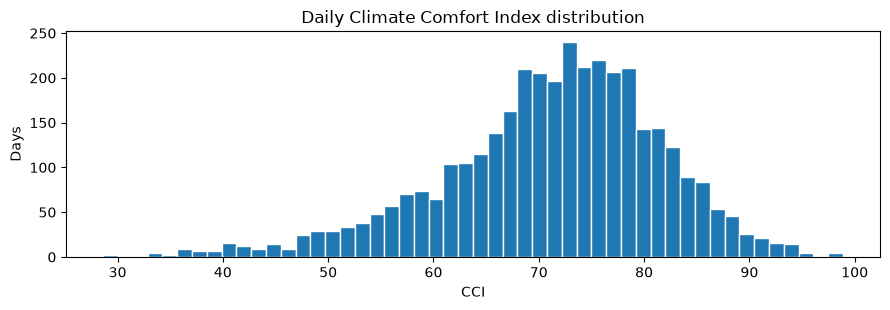

In [55]:
def calculate_cci(frame: pd.DataFrame) -> pd.DataFrame:
    """Add CCI component scores and the 0-100 daily Climate Comfort Index.

    Parameters
    ----------
    frame
        Daily-aggregated frame containing the five CCI input variables.

    Returns
    -------
    pd.DataFrame
        Copy of ``frame`` with five ``*_score`` columns and a ``cci`` column appended.
    """
    result = frame.copy()
    result["temp_score"] = (1 - (result["temperature_2m"] - 22).abs() / 20).clip(lower=0)
    result["humidity_score"] = (1 - (result["relative_humidity_2m"] - 50).abs() / 50).clip(lower=0)
    result["wind_score"] = (1 - (result["wind_speed_10m"] - 10).abs() / 40).clip(lower=0)
    result["cloud_score"] = (1 - result["cloud_cover"] / 100).clip(lower=0)
    result["rain_score"] = (1 - result["precipitation"] / 20).clip(lower=0)
    result["cci"] = 100 * (
        0.35 * result["temp_score"]
        + 0.20 * result["humidity_score"]
        + 0.15 * result["wind_score"]
        + 0.15 * result["cloud_score"]
        + 0.15 * result["rain_score"]
    )
    return result


SCORE_COLUMNS = ["temp_score", "humidity_score", "wind_score", "cloud_score", "rain_score"]
daily = calculate_cci(daily)

if not daily["cci"].dropna().between(0, 100).all():
    raise ValueError("CCI fell outside the documented 0-100 range.")

print("Component saturation (share of observed days scoring exactly 0):")
print((daily[SCORE_COLUMNS].dropna() == 0).mean().sort_values(ascending=False).to_string(float_format="{:.1%}".format))

BANDS = pd.IntervalIndex.from_breaks([0, 20, 40, 60, 80, 100.01], closed="left")
BAND_LABELS = ["Very poor (0-19)", "Poor (20-39)", "Moderate (40-59)",
               "Comfortable (60-79)", "Excellent (80-100)"]
band_counts = (
    pd.cut(daily["cci"], bins=BANDS).cat.rename_categories(BAND_LABELS)
    .value_counts().reindex(BAND_LABELS)
)
print("\nInterpretation bands:")
print(pd.DataFrame({"days": band_counts, "share": band_counts / band_counts.sum()})
      .to_string(formatters={"share": "{:.1%}".format}))

ax = daily["cci"].plot.hist(bins=50, figsize=(9, 3.2), color="tab:blue", edgecolor="white")
ax.set(title="Daily Climate Comfort Index distribution", xlabel="CCI", ylabel="Days")
ax.figure.tight_layout()


## 3. Feature engineering

CCI on day *t* alone is a weak feature set: it collapses five variables into one number, so a
hot dry day and a mild overcast day scoring the same value become indistinguishable despite
having very different likely futures. The feature set therefore keeps the raw daily variables
and their recent history alongside the index itself.

Each family below is built by its own function and documented in its own section, so the
purpose of every column is stated before it is created. `build_features` in section 3.9
composes them into the final matrix.

**The leakage rule applied throughout:** every column is produced by `shift(k)` with `k >= 0`,
or by a rolling window that is left-closed and ends at *t*. `center=True` is never used, as it
would look forward. Section 6 verifies this empirically by rebuilding features from a truncated
series.

| Section | Family | Columns |
| --- | --- | --- |
| 3.1 | Same-day observations | one per daily variable |
| 3.2 | Same-day component scores and CCI | 6 |
| 3.3 | Lagged observations | base variables x 4 lags |
| 3.4 | Rolling means and standard deviations | 4 variables x 4 windows x 2 statistics |
| 3.5 | Rolling precipitation totals | 4 |
| 3.6 | Rolling gust maxima | 4 (if gusts were ingested) |
| 3.7 | Short-term deltas | base variables x 2 steps |
| 3.8 | Seasonal position | 2 |


### Plot helpers

Each family below is inspected visually as well as described. Two standard views are used:

- a **distribution grid**, one histogram per column, which exposes skew, zero-inflation,
  saturation against a bound, and implausible values that a mean and standard deviation would
  conceal;
- a **series grid**, one time series per column over the most recent two years, which shows
  whether a feature actually varies at the daily timescale the model operates on, and whether it
  carries the seasonal cycle.

Every figure is written to `reports/figures/comfort_climate/` so it can be referenced directly
from the report rather than re-generated.


In [56]:
def save_figure(fig, name: str) -> None:
    """Write a figure to the report figures directory under a stable name."""
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURE_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def _panel_grid(n: int, ncols: int, panel_height: float = 1.85):
    """Return a figure and a flat array of axes sized for ``n`` panels."""
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.0 * ncols, panel_height * nrows))
    axes = np.atleast_1d(axes).ravel()
    for axis in axes[n:]:
        axis.axis("off")
    return fig, axes[:n]


def distribution_grid(frame: pd.DataFrame, title: str, name: str, ncols: int = 4):
    """Plot a histogram for every column, one panel each.

    Distributions reveal skew, zero-inflation, saturation at a bound, and implausible values
    that summary statistics alone would hide.
    """
    columns = list(frame.columns)
    fig, axes = _panel_grid(len(columns), ncols)
    for axis, column in zip(axes, columns):
        values = frame[column].dropna()
        axis.hist(values, bins=40, color="tab:blue", edgecolor="white", linewidth=0.3)
        axis.set_title(column, fontsize=7)
        axis.tick_params(labelsize=6)
        axis.set_ylabel("")
    fig.suptitle(title, fontsize=11)
    fig.tight_layout()
    save_figure(fig, name)
    return fig


def series_grid(frame: pd.DataFrame, title: str, name: str, ncols: int = 4, years: int = 2):
    """Plot the most recent ``years`` of every column as a time series, one panel each.

    A window is used rather than the full history so that day-to-day behaviour stays legible.
    """
    window = frame.loc[frame.index > frame.index.max() - pd.DateOffset(years=years)]
    columns = list(window.columns)
    fig, axes = _panel_grid(len(columns), ncols)
    for axis, column in zip(axes, columns):
        axis.plot(window.index, window[column], color="tab:blue", lw=0.6)
        axis.set_title(column, fontsize=7)
        axis.tick_params(labelsize=5)
        for label in axis.get_xticklabels():
            label.set_rotation(30)
    fig.suptitle(f"{title} (last {years} years)", fontsize=11)
    fig.tight_layout()
    save_figure(fig, name)
    return fig


print("Plot helpers ready. Figures are written to "
      f"{FIGURE_DIR.relative_to(PROJECT_ROOT)} for use in the report.")


Plot helpers ready. Figures are written to reports/figures/comfort_climate for use in the report.


### 3.1 Same-day observations

The daily aggregates for day *t* itself. These are the strongest predictors at short horizons,
because tomorrow's weather resembles today's more than it resembles anything else available.

| Column | What it is | Why it is included |
| --- | --- | --- |
| `temperature_2m` | Mean 2 m air temperature on *t*, °C | The dominant CCI component (weight 0.35). Temperature is strongly autocorrelated day to day, so today's value anchors the next three. |
| `relative_humidity_2m` | Mean relative humidity on *t*, % | Second-heaviest component (0.20). Also a proxy for air-mass type: humid air masses persist and suppress the diurnal temperature range. |
| `wind_speed_10m` | Mean 10 m wind speed on *t*, km/h | CCI component (0.15). Elevated wind often accompanies a synoptic system that will still be present tomorrow. |
| `cloud_cover` | Mean total cloud cover on *t*, % | CCI component (0.15). Persistent overcast indicates an established system rather than a passing shower. |
| `precipitation` | Total precipitation on *t*, mm | CCI component (0.15). Rain days cluster, so a wet day raises the odds the next is wet too. |

The following are included only when present in the raw extract. None appears in the CCI
formula; each is included because it carries information about *where the weather is going*
that the formula inputs do not.

| Column | What it is | Why it is included |
| --- | --- | --- |
| `pressure_msl` | Mean sea-level pressure on *t*, hPa | The single most useful non-formula predictor. Low and falling pressure signals an approaching frontal system, which is precisely the multi-day change the model is being asked to anticipate. |
| `wind_gusts_10m` | Maximum gust on *t*, km/h | Distinguishes a steadily breezy day from a convectively unstable one. Instability today often means showers in the following days. |
| `dew_point_2m` | Mean dew point on *t*, °C | An absolute measure of moisture, unlike relative humidity which moves with temperature. Air-mass changes show up here more cleanly. |
| `apparent_temperature` | Mean feels-like temperature on *t*, °C | Combines temperature, humidity, wind and radiation. Included as a compact summary; expected to correlate with `temp_score` and may prove redundant. |
| `shortwave_radiation` | Mean incoming shortwave radiation on *t*, W/m² | An independent measure of effective cloudiness, less noisy than the cloud-cover percentage. |


In [57]:
def same_day_observations(frame: pd.DataFrame) -> pd.DataFrame:
    """Return the daily observations for day *t* itself.

    Parameters
    ----------
    frame
        Daily frame indexed by date.

    Returns
    -------
    pd.DataFrame
        One column per ingested daily variable, unshifted.
    """
    columns = [*CCI_COLUMNS, *sorted(available_optional)]
    return frame[columns].copy()


preview = same_day_observations(daily)
print(f"3.1 same-day observations: {preview.shape[1]} columns")
print(list(preview.columns))
preview.tail(3)


3.1 same-day observations: 6 columns
['temperature_2m', 'relative_humidity_2m', 'wind_speed_10m', 'cloud_cover', 'precipitation', 'wind_gusts_10m']


,temperature_2m,relative_humidity_2m,wind_speed_10m,cloud_cover,precipitation,wind_gusts_10m
time,,,,,,
2025-12-29,18.32,61.38,8.90,20.29,0.00,40.70
2025-12-30,18.80,64.29,8.35,41.67,0.00,40.00
2025-12-31,19.47,73.04,8.35,91.79,0.40,38.90


#### Visual check

Both views matter for this family. The distributions confirm the physical plausibility of each
variable and expose the shape of precipitation, which is heavily zero-inflated: most days record
no rain at all, and the mean is driven by a small number of large days. The series show which
variables carry a visible annual cycle — temperature strongly, cloud cover and wind much less —
which is the first evidence for including the seasonal encoding in section 3.8.


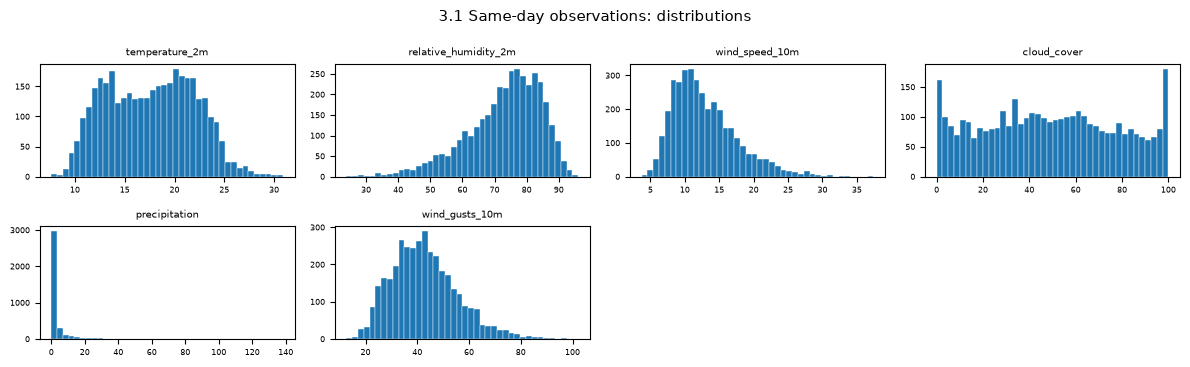

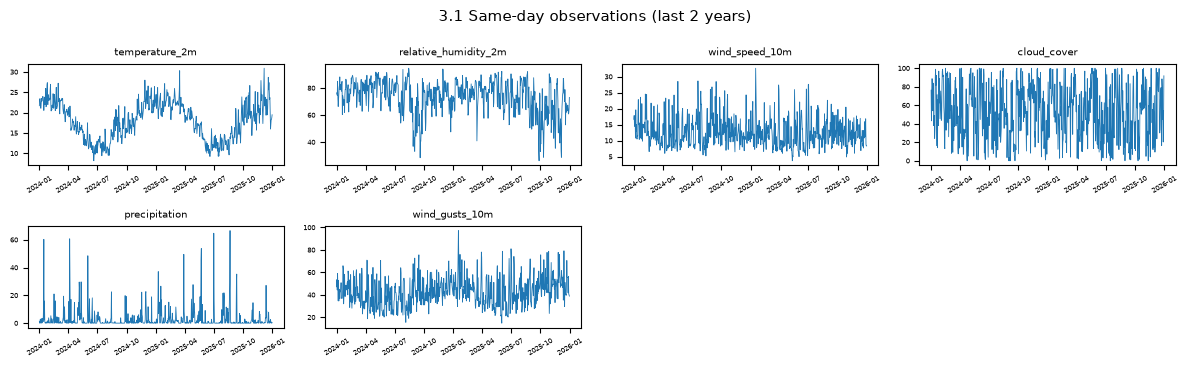

In [58]:
same_day_obs = same_day_observations(daily)
distribution_grid(same_day_obs, "3.1 Same-day observations: distributions",
                  "features-31-same-day-observations-dist")
series_grid(same_day_obs, "3.1 Same-day observations",
            "features-31-same-day-observations-series")
plt.show()


### 3.2 Same-day component scores and CCI

The five bounded component scores and the composite index for day *t*.

The raw variables in 3.1 and the scores here are not redundant with each other. A score encodes
*distance from the ideal*, which the raw value does not: 12°C and 32°C are far apart as
temperatures but score identically at 0.5. Supplying both lets a tree split on either the
physical value or the comfort penalty, whichever separates the target better.

| Column | What it is | Why it is included |
| --- | --- | --- |
| `temp_score` | `max(0, 1 - abs(T - 22) / 20)` on *t* | Distance from the 22°C comfort optimum, bounded to [0, 1]. Isolates the largest single driver of the target. |
| `humidity_score` | `max(0, 1 - abs(RH - 50) / 50)` on *t* | Distance from 50% RH. Symmetric, so it treats dry and muggy days as equally uncomfortable — information the raw percentage does not carry. |
| `wind_score` | `max(0, 1 - abs(W - 10) / 40)` on *t* | Distance from a 10 km/h light breeze. Penalises both still and gusty days. |
| `cloud_score` | `max(0, 1 - cloud / 100)` on *t* | Linear clear-sky preference. A monotone rescaling of cloud cover, retained so all five components are available on the same scale. |
| `rain_score` | `max(0, 1 - precip / 20)` on *t* | Dryness score, saturating at zero for any day of 20 mm or more. The saturation rate is reported in section 2. |
| `cci` | Weighted sum of the five scores, 0–100 | The persistence feature and the basis of the baseline model. This is the same quantity as the target, observed on *t* rather than *t+h*, which makes it legitimate: it is known at prediction time. |


In [59]:
def same_day_scores(frame: pd.DataFrame) -> pd.DataFrame:
    """Return the five CCI component scores and the composite index for day *t*."""
    return frame[[*SCORE_COLUMNS, "cci"]].copy()


preview = same_day_scores(daily)
print(f"3.2 same-day scores: {preview.shape[1]} columns")
preview.tail(3)


3.2 same-day scores: 6 columns


,temp_score,humidity_score,wind_score,cloud_score,rain_score,cci
time,,,,,,
2025-12-29,0.82,0.77,0.97,0.80,1.00,85.55
2025-12-30,0.84,0.71,0.96,0.58,1.00,81.81
2025-12-31,0.87,0.54,0.96,0.08,0.98,71.66


#### Visual check

The score distributions should look markedly different from the raw variables they derive from.
Look for the spike at zero in `rain_score` (every day of 20 mm or more collapses to the same
value) and the compression of `temp_score` toward the upper end, which reflects Sydney sitting
close to the 22°C optimum for much of the year. A component whose distribution is nearly
constant contributes little discriminating power to the target, which is worth knowing before
model fitting rather than after.


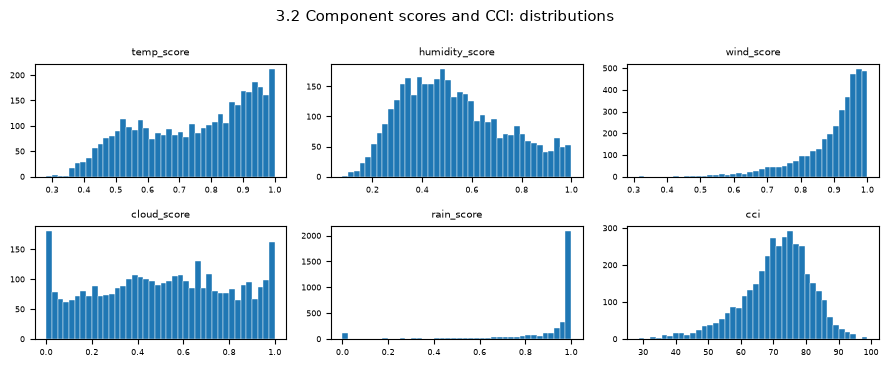

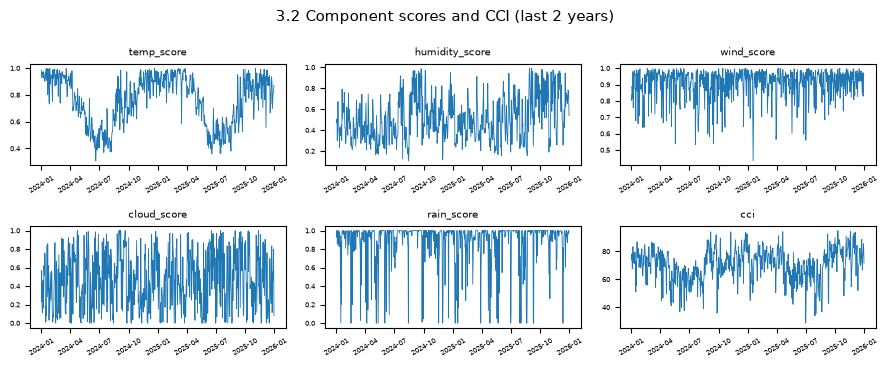

In [60]:
same_day_score_frame = same_day_scores(daily)
distribution_grid(same_day_score_frame, "3.2 Component scores and CCI: distributions",
                  "features-32-scores-dist", ncols=3)
series_grid(same_day_score_frame, "3.2 Component scores and CCI",
            "features-32-scores-series", ncols=3)
plt.show()


### 3.3 Lagged observations

Values from *t*−1, *t*−2, *t*−3 and *t*−7, produced with `shift(k)` for positive `k`.

A single day is a snapshot. Lags give the model a short trajectory, so it can distinguish a warm
day at the end of a cooling trend from a warm day at the start of a heatwave — two states with
the same `temperature_2m` and very different futures.

**What each lag distance contributes**

| Lag | Column suffix | Purpose |
| --- | --- | --- |
| 1 day | `_lag1` | Yesterday. Combined with the same-day value it gives the immediate direction of travel. |
| 2 days | `_lag2` | Extends the trajectory enough to distinguish a steady trend from a one-day fluctuation. |
| 3 days | `_lag3` | Roughly the residence time of a synoptic system over Sydney, so it captures the current system as a whole. |
| 7 days | `_lag7` | The same weekday one week earlier. Serves as a short-term local climatology reference, largely free of the seasonal drift that a 30-day lag would carry. |

**Which variables are lagged**

| Base variable | Columns generated | What the history adds |
| --- | --- | --- |
| `temperature_2m` | `temperature_2m_lag{1,2,3,7}` | Warming or cooling trend, and its steepness. |
| `relative_humidity_2m` | `relative_humidity_2m_lag{1,2,3,7}` | Moistening or drying, which typically precedes a change in cloud and rain. |
| `wind_speed_10m` | `wind_speed_10m_lag{1,2,3,7}` | Whether wind is building or easing — building wind often precedes a front. |
| `cloud_cover` | `cloud_cover_lag{1,2,3,7}` | Whether cloud is thickening or clearing. |
| `precipitation` | `precipitation_lag{1,2,3,7}` | Recent rain history, which clusters strongly. |
| `cci` | `cci_lag{1,2,3,7}` | The trajectory of the target itself; the most direct trend signal available. |
| optional variables | `pressure_msl_lag{...}`, etc. | Pressure lags are the most valuable here: the *change* in pressure over several days is the classic frontal indicator, and section 3.7 derives it from these. |


In [61]:
# Lag every ingested daily variable plus the index itself.
LAG_BASE = [*CCI_COLUMNS, "cci", *sorted(available_optional)]


def lagged_observations(frame: pd.DataFrame) -> pd.DataFrame:
    """Return values from *t*-1, *t*-2, *t*-3 and *t*-7 for each base variable.

    Uses positive shifts only, so every column depends solely on the past.
    """
    return pd.DataFrame(
        {f"{column}_lag{lag}": frame[column].shift(lag)
         for column in LAG_BASE for lag in LAG_DAYS},
        index=frame.index,
    )


preview = lagged_observations(daily)
print(f"3.3 lagged observations: {preview.shape[1]} columns "
      f"({len(LAG_BASE)} variables x {len(LAG_DAYS)} lags)")
preview.tail(3).iloc[:, :4]


3.3 lagged observations: 28 columns (7 variables x 4 lags)


,temperature_2m_lag1,temperature_2m_lag2,temperature_2m_lag3,temperature_2m_lag7
time,,,,
2025-12-29,18.22,17.06,15.96,25.49
2025-12-30,18.32,18.22,17.06,23.29
2025-12-31,18.80,18.32,18.22,23.69


#### Visual check

A lagged column has the same marginal distribution as its source, so histograms of all 28 add
little. The informative view is how the relationship with the present decays as the lag grows.

The first figure plots the correlation between each base variable at *t* and the same variable
at each lag. A slow decay means the variable is highly persistent, so its lags are largely
redundant with the same-day value; a steep decay means each lag carries new information. This is
the evidence for keeping or dropping lag depth, and should be read alongside the ablation
results in the modelling notebook.

The second figure overlays `cci` with its own lags over a short window, making the shift visible
directly and confirming the lags move backwards in time, never forwards.


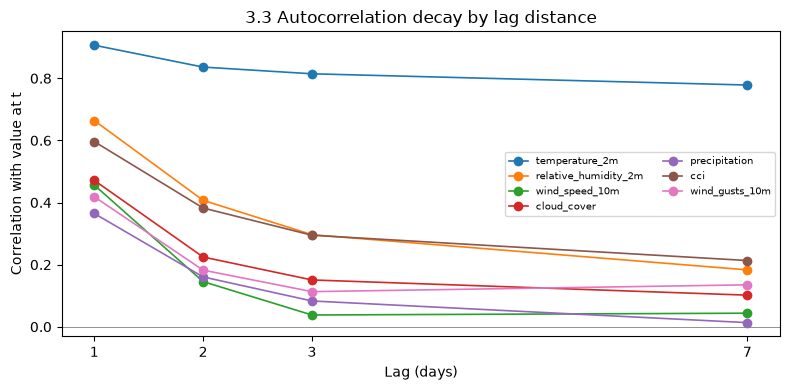

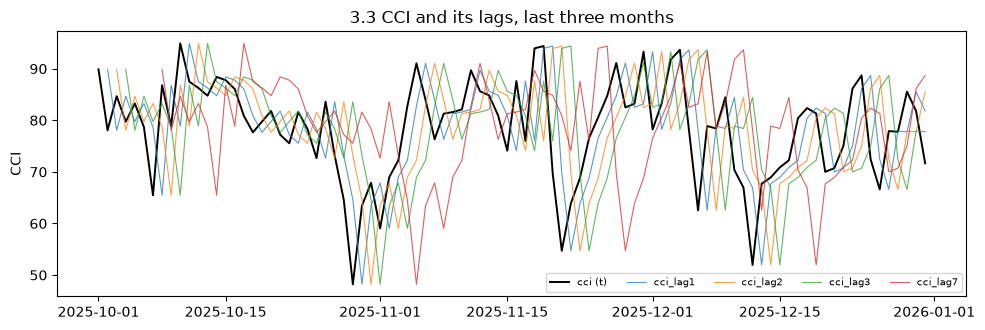

In [62]:
lag_frame = lagged_observations(daily)

fig, axis = plt.subplots(figsize=(8, 4))
for column in LAG_BASE:
    correlations = [daily[column].corr(daily[column].shift(lag)) for lag in LAG_DAYS]
    axis.plot(LAG_DAYS, correlations, marker="o", lw=1.2, label=column)
axis.set(title="3.3 Autocorrelation decay by lag distance", xlabel="Lag (days)",
         ylabel="Correlation with value at t", xticks=LAG_DAYS)
axis.axhline(0, color="grey", lw=0.6)
axis.legend(fontsize=7, ncol=2)
fig.tight_layout()
save_figure(fig, "features-33-lag-autocorrelation")

recent = daily.loc[daily.index > daily.index.max() - pd.DateOffset(months=3)]
fig, axis = plt.subplots(figsize=(10, 3.4))
axis.plot(recent.index, recent["cci"], color="black", lw=1.4, label="cci (t)")
for lag in LAG_DAYS:
    axis.plot(recent.index, recent["cci"].shift(lag), lw=0.8, alpha=0.75, label=f"cci_lag{lag}")
axis.set(title="3.3 CCI and its lags, last three months", ylabel="CCI")
axis.legend(fontsize=7, ncol=5)
fig.tight_layout()
save_figure(fig, "features-33-cci-lags-overlay")
plt.show()


### 3.4 Rolling means and standard deviations

Windows of 3, 7, 14 and 30 days ending on *t*, for four variables, giving a mean and a standard
deviation each.

Individual lags are noisy — one unusual day moves them a lot. A rolling mean is a smoothed
estimate of the current regime, and the standard deviation over the same window says how settled
that regime is. Volatility is separately useful: a stable high-pressure spell is far more
predictable three days out than an unsettled one, and the model can learn to lean harder on
persistence when the recent standard deviation is low.

Multiple window lengths are provided rather than one because they measure different things: 3
days is the current system, 30 days is the season-to-date baseline, and 7 and 14 sit between.

| Base variable | Columns generated | What the mean captures | What the standard deviation captures |
| --- | --- | --- | --- |
| `temperature_2m` | `temperature_2m_roll{3,7,14,30}_{mean,std}` | The prevailing thermal regime, and via the 30-day window an implicit local climatology the model can use as a fallback. | Temperature variability — high values indicate frontal passages rather than a settled air mass. |
| `relative_humidity_2m` | `relative_humidity_2m_roll{3,7,14,30}_{mean,std}` | Whether the period has been broadly humid or dry. | Swings in moisture, which accompany air-mass changes. |
| `cloud_cover` | `cloud_cover_roll{3,7,14,30}_{mean,std}` | Sustained cloudiness versus intermittent cover. | Whether cloud has been consistent or alternating. |
| `cci` | `cci_roll{3,7,14,30}_{mean,std}` | The recent comfort level, smoothed. The 30-day mean is close to a seasonal climatology estimate. | Comfort volatility, a direct measure of how hard the coming days are likely to be to predict. |

`min_periods` is set equal to the window, so a partial window yields `NaN` rather than a value
computed from fewer days. Those rows are removed by the warm-up filter in section 4 instead of
being silently filled.


In [63]:
# Variables smooth enough for a rolling mean to be meaningful. Precipitation and gusts are
# excluded here and handled in 3.5 and 3.6, where a sum and a maximum are the right statistics.
ROLL_STAT_BASE = ["temperature_2m", "relative_humidity_2m", "cloud_cover", "cci"]


def rolling_statistics(frame: pd.DataFrame) -> pd.DataFrame:
    """Return rolling means and standard deviations over windows ending on *t*.

    Windows are left-closed (``center`` is left at its default of ``False``) and require a full
    window, so no value depends on a future observation.
    """
    columns = {}
    for column in ROLL_STAT_BASE:
        window_source = frame[column]
        for window in ROLLING_WINDOWS:
            rolled = window_source.rolling(window, min_periods=window)
            columns[f"{column}_roll{window}_mean"] = rolled.mean()
            columns[f"{column}_roll{window}_std"] = rolled.std()
    return pd.DataFrame(columns, index=frame.index)


preview = rolling_statistics(daily)
print(f"3.4 rolling statistics: {preview.shape[1]} columns "
      f"({len(ROLL_STAT_BASE)} variables x {len(ROLLING_WINDOWS)} windows x 2 statistics)")
preview.tail(3).iloc[:, :4]


3.4 rolling statistics: 32 columns (4 variables x 4 windows x 2 statistics)


,temperature_2m_roll3_mean,temperature_2m_roll3_std,temperature_2m_roll7_mean,temperature_2m_roll7_std
time,,,,
2025-12-29,17.87,0.70,19.43,2.98
2025-12-30,18.45,0.31,18.79,2.45
2025-12-31,18.86,0.58,18.19,1.29


#### Visual check

Three views are used here because means and standard deviations do different jobs.

The first shows each rolling mean overlaid on the raw daily series: longer windows should trace
a progressively smoother path, with the 30-day mean approximating a seasonal baseline rather
than tracking individual weather systems. If a long window looks as jagged as the raw series,
the smoothing is not working as intended.

The second plots the rolling standard deviations, which measure how unsettled the recent period
has been. Peaks should coincide with visibly volatile stretches in the first figure.

The third gives the full distribution grid so that every one of the 32 columns is inspected, not
only the representative ones.


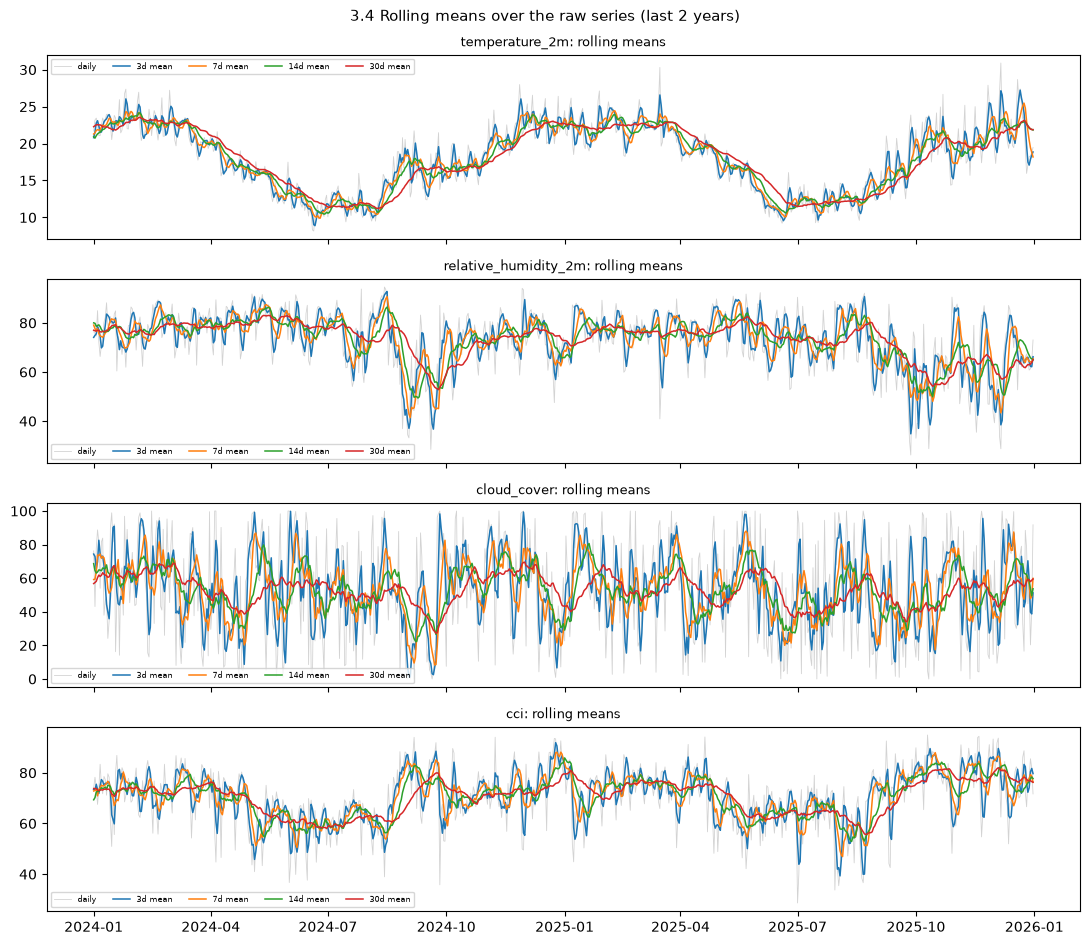

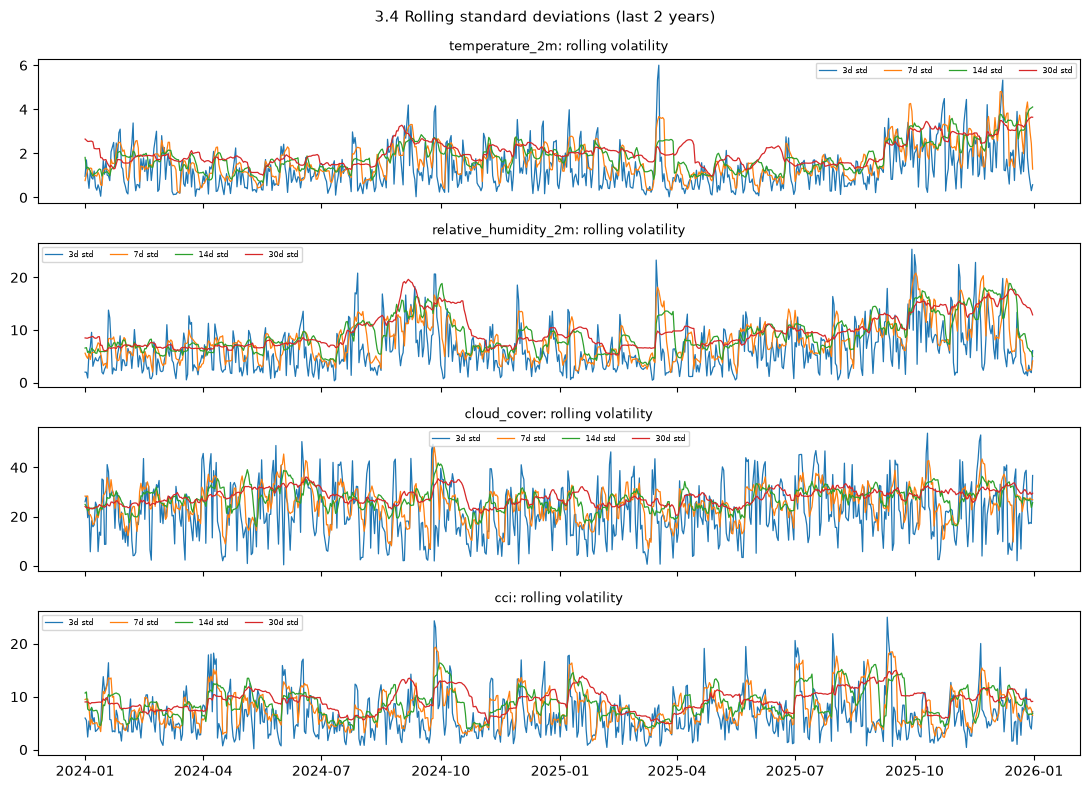

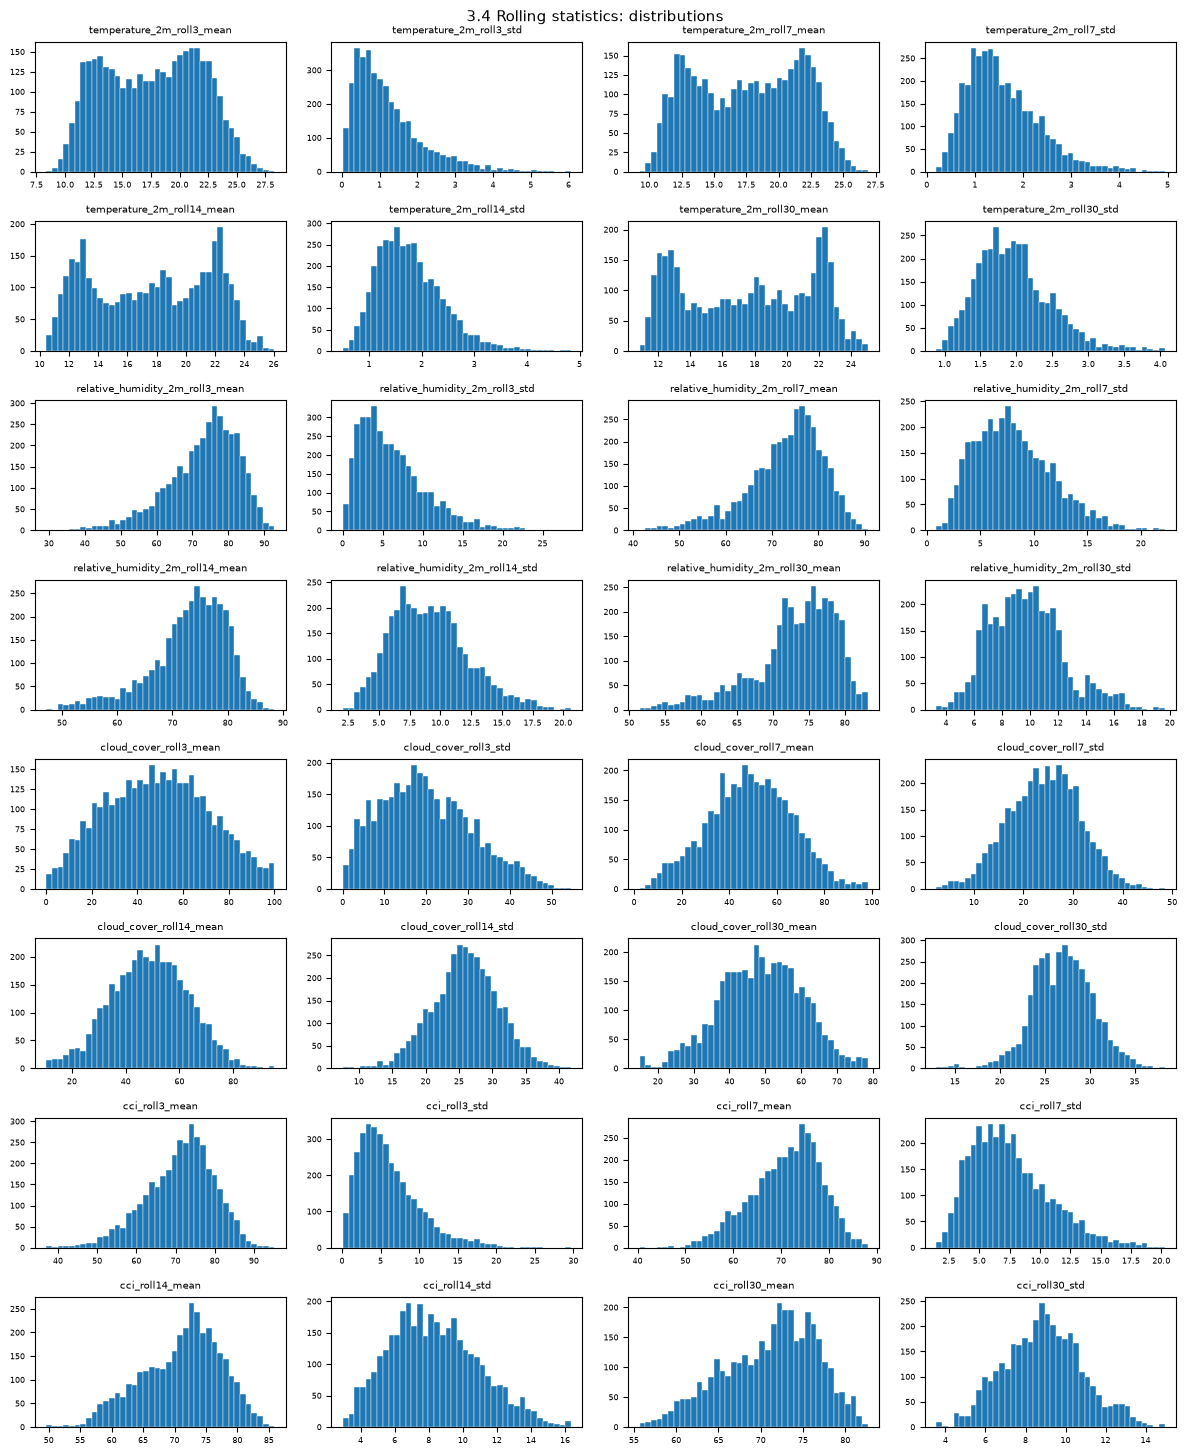

In [64]:
rolling_frame = rolling_statistics(daily)
window_years = 2
recent = daily.loc[daily.index > daily.index.max() - pd.DateOffset(years=window_years)]

fig, axes = plt.subplots(len(ROLL_STAT_BASE), 1, figsize=(11, 2.4 * len(ROLL_STAT_BASE)),
                         sharex=True)
for axis, column in zip(np.atleast_1d(axes), ROLL_STAT_BASE):
    axis.plot(recent.index, recent[column], color="lightgrey", lw=0.6, label="daily")
    for window in ROLLING_WINDOWS:
        smoothed = rolling_frame[f"{column}_roll{window}_mean"].reindex(recent.index)
        axis.plot(recent.index, smoothed, lw=1.1, label=f"{window}d mean")
    axis.set_title(f"{column}: rolling means", fontsize=9)
    axis.legend(fontsize=6, ncol=5)
fig.suptitle(f"3.4 Rolling means over the raw series (last {window_years} years)", fontsize=11)
fig.tight_layout()
save_figure(fig, "features-34-rolling-means-overlay")

fig, axes = plt.subplots(len(ROLL_STAT_BASE), 1, figsize=(11, 2.0 * len(ROLL_STAT_BASE)),
                         sharex=True)
for axis, column in zip(np.atleast_1d(axes), ROLL_STAT_BASE):
    for window in ROLLING_WINDOWS:
        volatility = rolling_frame[f"{column}_roll{window}_std"].reindex(recent.index)
        axis.plot(recent.index, volatility, lw=0.9, label=f"{window}d std")
    axis.set_title(f"{column}: rolling volatility", fontsize=9)
    axis.legend(fontsize=6, ncol=4)
fig.suptitle(f"3.4 Rolling standard deviations (last {window_years} years)", fontsize=11)
fig.tight_layout()
save_figure(fig, "features-34-rolling-std-series")

distribution_grid(rolling_frame, "3.4 Rolling statistics: distributions",
                  "features-34-rolling-dist")
plt.show()


### 3.5 Rolling precipitation totals

Precipitation is summed, not averaged. A mean daily rainfall over a window is hard to interpret
and loses the quantity that matters, which is how much water has actually fallen.

| Column | What it is | Why it is included |
| --- | --- | --- |
| `precipitation_roll3_sum` | Total rainfall over *t*−2 to *t*, mm | Identifies an active wet spell. Consecutive wet days indicate a stalled system likely to persist into the forecast window. |
| `precipitation_roll7_sum` | Total rainfall over the week ending *t*, mm | Weekly wetness, smoothing over individual dry days within an unsettled period. |
| `precipitation_roll14_sum` | Total rainfall over the fortnight ending *t*, mm | Medium-term wetness, useful for separating a genuinely wet month from an isolated storm. |
| `precipitation_roll30_sum` | Total rainfall over the month ending *t*, mm | Approximates the prevailing regime — drought versus a wet pattern — which shifts the base rate of rain in the coming days. |

Rainfall is heavily zero-inflated and right-skewed, so these totals are dominated by a small
number of large days. That is expected and is why the distribution is inspected in section 2
rather than assumed to be well behaved.


In [65]:
def rolling_precipitation(frame: pd.DataFrame) -> pd.DataFrame:
    """Return accumulated rainfall over windows ending on *t*."""
    return pd.DataFrame(
        {f"precipitation_roll{window}_sum":
         frame["precipitation"].rolling(window, min_periods=window).sum()
         for window in ROLLING_WINDOWS},
        index=frame.index,
    )


preview = rolling_precipitation(daily)
print(f"3.5 rolling precipitation totals: {preview.shape[1]} columns")
preview.tail(3)


3.5 rolling precipitation totals: 4 columns


,precipitation_roll3_sum,precipitation_roll7_sum,precipitation_roll14_sum,precipitation_roll30_sum
time,,,,
2025-12-29,1.30,5.80,16.40,68.00
2025-12-30,0.80,5.80,16.00,67.50
2025-12-31,0.40,6.20,16.40,67.70


#### Visual check

Rainfall totals are strongly right-skewed, so the histograms are drawn on a logarithmic count
axis; on a linear axis the zero bar dominates and the tail that actually drives `rain_score`
becomes invisible.

The series view shows accumulation behaviour: short windows spike and reset, while the 30-day
total moves slowly and acts as a wet-or-dry regime indicator. Comparing the two makes clear why
several window lengths are retained rather than one.


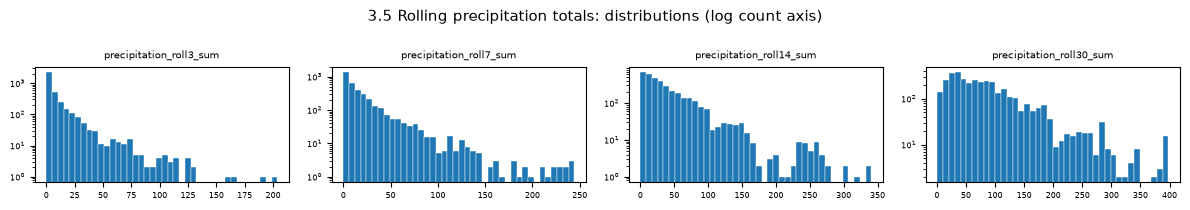

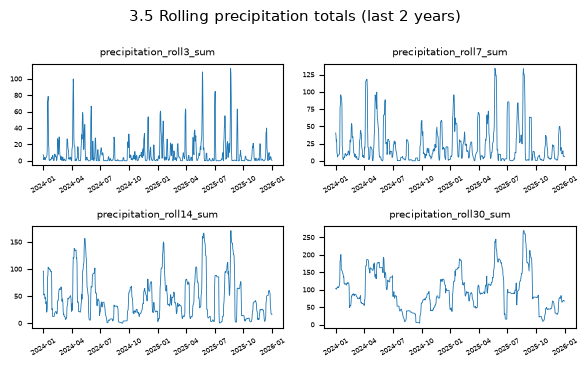

In [66]:
precipitation_frame = rolling_precipitation(daily)

columns = list(precipitation_frame.columns)
fig, axes = _panel_grid(len(columns), min(4, len(columns)), panel_height=2.1)
for axis, column in zip(axes, columns):
    axis.hist(precipitation_frame[column].dropna(), bins=40, color="tab:blue",
              edgecolor="white", linewidth=0.3)
    axis.set_yscale("log")
    axis.set_title(column, fontsize=7)
    axis.tick_params(labelsize=6)
fig.suptitle("3.5 Rolling precipitation totals: distributions (log count axis)", fontsize=11)
fig.tight_layout()
save_figure(fig, "features-35-precipitation-dist")

series_grid(precipitation_frame, "3.5 Rolling precipitation totals",
            "features-35-precipitation-series", ncols=2)
plt.show()


### 3.6 Rolling gust maxima

Built only when `wind_gusts_10m` was ingested.

Gusts are summarised with a maximum rather than a mean, because the meteorologically meaningful
quantity is the strongest gust the window contained, not its typical value. Averaging would
dilute exactly the extreme this feature exists to capture.

| Column | What it is | Why it is included |
| --- | --- | --- |
| `wind_gusts_10m_roll3_max` | Strongest gust over *t*−2 to *t*, km/h | Flags a recent convective or frontal event. Such systems typically take more than three days to clear, so the marker remains relevant across the whole forecast horizon. |
| `wind_gusts_10m_roll7_max` | Strongest gust in the week ending *t*, km/h | Distinguishes a genuinely stormy week from a calm one. |
| `wind_gusts_10m_roll14_max` | Strongest gust in the fortnight ending *t*, km/h | Medium-term storminess of the current pattern. |
| `wind_gusts_10m_roll30_max` | Strongest gust in the month ending *t*, km/h | Seasonal-scale windiness; slow-moving and close to a local climatology term. |

These features are more directly motivated by the hazard task than by comfort, since gusts do
not enter the CCI formula. They are retained here because storminess suppresses comfort through
the cloud, rain and wind components together, and because keeping the two pipelines aligned lets
the same feature builder serve both targets.


In [67]:
def rolling_gusts(frame: pd.DataFrame) -> pd.DataFrame:
    """Return peak gusts over windows ending on *t*, or an empty frame if gusts are absent."""
    if "wind_gusts_10m" not in frame.columns:
        return pd.DataFrame(index=frame.index)
    return pd.DataFrame(
        {f"wind_gusts_10m_roll{window}_max":
         frame["wind_gusts_10m"].rolling(window, min_periods=window).max()
         for window in ROLLING_WINDOWS},
        index=frame.index,
    )


preview = rolling_gusts(daily)
print(f"3.6 rolling gust maxima: {preview.shape[1]} columns"
      f"{'' if preview.shape[1] else ' (wind_gusts_10m not ingested)'}")
preview.tail(3)


3.6 rolling gust maxima: 4 columns


,wind_gusts_10m_roll3_max,wind_gusts_10m_roll7_max,wind_gusts_10m_roll14_max,wind_gusts_10m_roll30_max
time,,,,
2025-12-29,56.50,70.60,70.60,79.20
2025-12-30,56.50,56.50,70.60,79.20
2025-12-31,40.70,56.50,70.60,79.20


#### Visual check

Peak gusts should form a series of plateaus: a single storm sets the maximum, which then holds
until it drops out of the window. Longer windows plateau for longer. Seeing that staircase shape
confirms the maximum is behaving as intended rather than averaging the extremes away.

The distributions are expected to shift right as the window lengthens, since a longer window has
more opportunities to contain a strong gust.


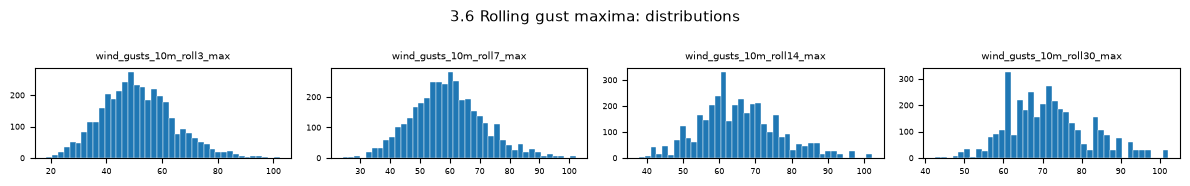

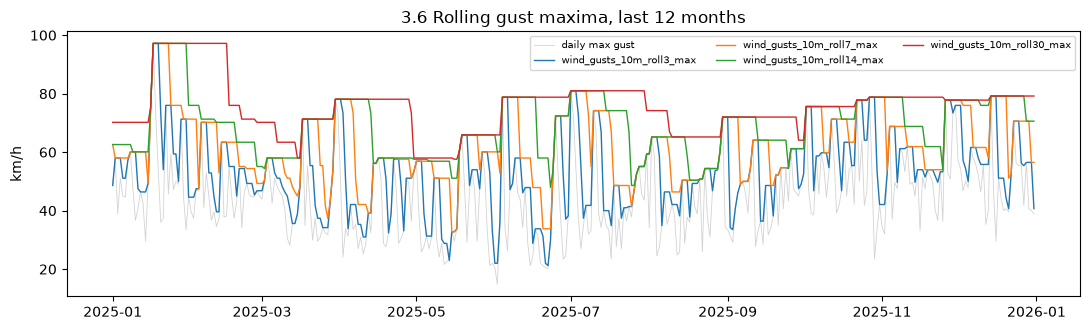

In [68]:
gust_frame = rolling_gusts(daily)
if gust_frame.empty:
    print("wind_gusts_10m was not ingested; no gust features to plot.")
else:
    distribution_grid(gust_frame, "3.6 Rolling gust maxima: distributions",
                      "features-36-gusts-dist", ncols=min(4, gust_frame.shape[1]))
    recent = gust_frame.loc[gust_frame.index > gust_frame.index.max() - pd.DateOffset(years=1)]
    fig, axis = plt.subplots(figsize=(11, 3.4))
    if "wind_gusts_10m" in daily:
        axis.plot(recent.index, daily["wind_gusts_10m"].reindex(recent.index),
                  color="lightgrey", lw=0.6, label="daily max gust")
    for column in gust_frame.columns:
        axis.plot(recent.index, recent[column], lw=1.0, label=column)
    axis.set(title="3.6 Rolling gust maxima, last 12 months", ylabel="km/h")
    axis.legend(fontsize=7, ncol=3)
    fig.tight_layout()
    save_figure(fig, "features-36-gusts-series")
plt.show()


### 3.7 Short-term deltas

The change in a variable between *t*−k and *t*, for k of 1 and 3 days.

A tree ensemble cannot form a difference between two columns on its own — it splits on one
feature at a time, so `temperature_2m` and `temperature_2m_lag3` being both present does not let
it act on the gap between them without spending many splits approximating it. Providing the
difference directly makes the trend available in a single split.

Two step sizes are used: 1 day for the immediate direction, and 3 days for the trend across the
current synoptic system.

| Column | What it is | Why it is included |
| --- | --- | --- |
| `temperature_2m_delta1` | *t* minus *t*−1 temperature, °C | Yesterday-to-today warming or cooling. Large negative values typically follow a cool change. |
| `temperature_2m_delta3` | *t* minus *t*−3 temperature, °C | Sustained thermal trend, less sensitive to a single unusual day. |
| `cci_delta1` | *t* minus *t*−1 CCI | Whether comfort is improving or deteriorating right now. |
| `cci_delta3` | *t* minus *t*−3 CCI | The direction of the current comfort regime; the closest thing available to a momentum term on the target. |
| `pressure_msl_delta1` | *t* minus *t*−1 pressure, hPa | Built only if pressure was ingested. The standard short-range frontal indicator: a sharp fall precedes wind, cloud and rain, all of which suppress CCI within the forecast window. |
| `pressure_msl_delta3` | *t* minus *t*−3 pressure, hPa | Distinguishes a deepening system from a transient wobble in the barometer. |

Of all engineered features, the pressure deltas are the most likely to add information the
formula inputs cannot supply, because they describe the atmosphere's *tendency* rather than its
current state. Whether they earn their place is tested in the modelling ablation rather than
assumed here.


In [69]:
# Pressure is included only when ingested; it is the most informative delta available.
DELTA_BASE = ["temperature_2m", "cci"] + (["pressure_msl"] if "pressure_msl" in daily else [])
DELTA_STEPS = (1, 3)


def short_term_deltas(frame: pd.DataFrame) -> pd.DataFrame:
    """Return the change in each base variable between *t*-k and *t*."""
    return pd.DataFrame(
        {f"{column}_delta{step}": frame[column] - frame[column].shift(step)
         for column in DELTA_BASE for step in DELTA_STEPS},
        index=frame.index,
    )


preview = short_term_deltas(daily)
print(f"3.7 short-term deltas: {preview.shape[1]} columns "
      f"({len(DELTA_BASE)} variables x {len(DELTA_STEPS)} steps)")
preview.tail(3)


3.7 short-term deltas: 4 columns (2 variables x 2 steps)


,temperature_2m_delta1,temperature_2m_delta3,cci_delta1,cci_delta3
time,,,,
2025-12-29,0.09,2.36,7.77,18.94
2025-12-30,0.48,1.74,-3.73,3.90
2025-12-31,0.67,1.24,-10.15,-6.11


#### Visual check

Deltas should be centred on zero and roughly symmetric: over a long record the atmosphere warms
as often as it cools. A visible offset would indicate a trend or a construction error.

The three-day deltas should be wider than the one-day deltas, since more can change over a
longer interval. The tails are the interesting part — the extreme negative `temperature_2m_delta1`
values are Sydney's southerly busters, and these are exactly the abrupt transitions that make
the next few days hard to predict from persistence alone.

The scatter relates each delta to the concurrent change in CCI, showing whether the mechanism
the feature is meant to capture is actually present in the data.


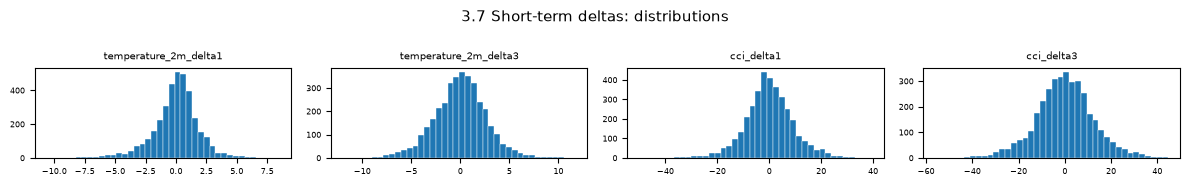

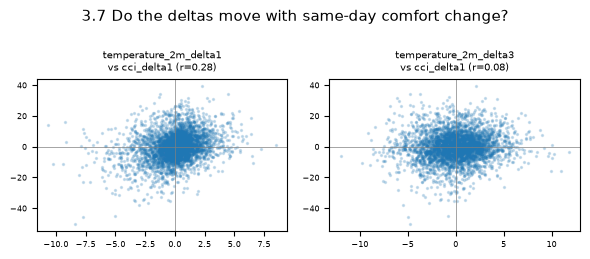

In [70]:
delta_frame = short_term_deltas(daily)
distribution_grid(delta_frame, "3.7 Short-term deltas: distributions",
                  "features-37-deltas-dist", ncols=min(4, delta_frame.shape[1]))

drivers = [c for c in delta_frame.columns if not c.startswith("cci_")]
fig, axes = _panel_grid(len(drivers), min(4, len(drivers)), panel_height=2.6)
for axis, column in zip(axes, drivers):
    axis.scatter(delta_frame[column], delta_frame["cci_delta1"], s=2, alpha=0.2,
                 color="tab:blue")
    axis.axhline(0, color="grey", lw=0.5)
    axis.axvline(0, color="grey", lw=0.5)
    correlation = delta_frame[column].corr(delta_frame["cci_delta1"])
    axis.set_title(f"{column}\nvs cci_delta1 (r={correlation:.2f})", fontsize=7)
    axis.tick_params(labelsize=6)
fig.suptitle("3.7 Do the deltas move with same-day comfort change?", fontsize=11)
fig.tight_layout()
save_figure(fig, "features-37-deltas-vs-cci")
plt.show()


### 3.8 Seasonal position

Day-of-year encoded as a sine and cosine pair.

Sydney's comfort distribution differs sharply between seasons, so the calendar position carries
real predictive weight independently of current conditions: a 25°C day in October and a 25°C day
in February sit in different regimes and have different likely successors.

The obvious encoding — day-of-year as an integer from 1 to 365 — introduces an artificial
discontinuity at the year boundary, where 31 December and 1 January are one day apart in reality
but 364 apart numerically. A tree would have to spend splits repairing that. Projecting the
angle onto a sine and cosine pair removes the seam: the two columns together locate the day on a
circle, so late December and early January are correctly adjacent.

| Column | What it is | Why it is included |
| --- | --- | --- |
| `doy_sin` | `sin(2 x pi x day_of_year / 365.25)` | One coordinate of the calendar position on the annual cycle. |
| `doy_cos` | `cos(2 x pi x day_of_year / 365.25)` | The other coordinate. Both are required: either alone is ambiguous, since one value maps to two dates in the year. |

`365.25` is used rather than `365` so that the phase does not drift across leap years.

These are the only features that are not derived from observations at all. They are computable
for any future date, which makes them the one part of the feature vector the API can always
construct without an archive lookup.


In [71]:
def seasonal_position(frame: pd.DataFrame) -> pd.DataFrame:
    """Return day-of-year as a sine/cosine pair, avoiding the 31 Dec to 1 Jan discontinuity."""
    day_of_year = frame.index.dayofyear
    angle = 2 * np.pi * day_of_year / 365.25
    return pd.DataFrame(
        {"doy_sin": np.sin(angle), "doy_cos": np.cos(angle)}, index=frame.index
    )


preview = seasonal_position(daily)
print(f"3.8 seasonal position: {preview.shape[1]} columns")
preview.tail(3)


3.8 seasonal position: 2 columns


,doy_sin,doy_cos
time,,
2025-12-29,-0.04,1.00
2025-12-30,-0.02,1.00
2025-12-31,-0.00,1.00


#### Visual check

The first figure plots both encodings against day-of-year and shows the pair traced as a circle.
The circle is the point of the encoding: 31 December and 1 January sit adjacent on it, whereas an
integer day-of-year would place them 364 apart and force the model to spend splits repairing the
seam.

The second figure is the justification for including seasonality at all. It plots mean CCI by
day-of-year across the record: if comfort varies systematically through the year, the calendar
position carries predictive information that no same-day observation supplies, and the encoding
earns its place. A flat curve would mean these two columns are dead weight.


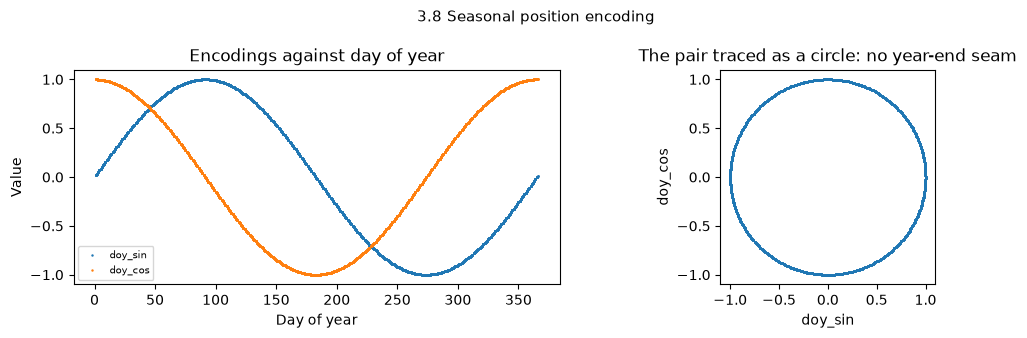

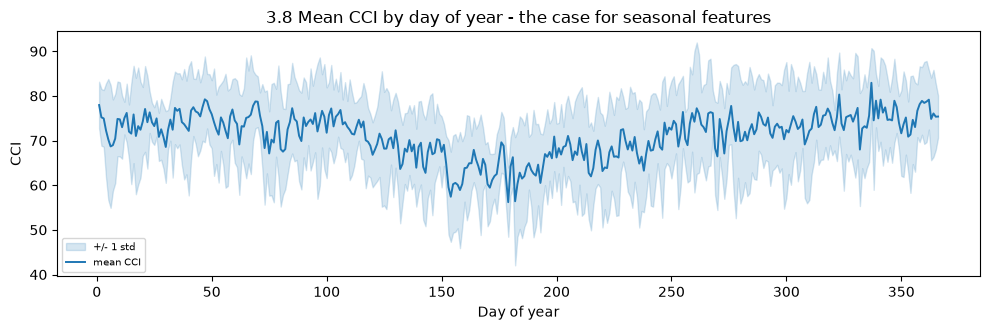

In [72]:
seasonal_frame = seasonal_position(daily)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
day_of_year = daily.index.dayofyear
axes[0].plot(day_of_year, seasonal_frame["doy_sin"], ".", ms=1.5, label="doy_sin")
axes[0].plot(day_of_year, seasonal_frame["doy_cos"], ".", ms=1.5, label="doy_cos")
axes[0].set(title="Encodings against day of year", xlabel="Day of year", ylabel="Value")
axes[0].legend(fontsize=7)
axes[1].plot(seasonal_frame["doy_sin"], seasonal_frame["doy_cos"], ".", ms=1.5,
             color="tab:blue")
axes[1].set(title="The pair traced as a circle: no year-end seam",
            xlabel="doy_sin", ylabel="doy_cos")
axes[1].set_aspect("equal")
fig.suptitle("3.8 Seasonal position encoding", fontsize=11)
fig.tight_layout()
save_figure(fig, "features-38-seasonal-encoding")

seasonal_profile = daily.groupby(daily.index.dayofyear)["cci"].agg(["mean", "std"])
fig, axis = plt.subplots(figsize=(10, 3.4))
axis.fill_between(seasonal_profile.index,
                  seasonal_profile["mean"] - seasonal_profile["std"],
                  seasonal_profile["mean"] + seasonal_profile["std"],
                  color="tab:blue", alpha=0.18, label="+/- 1 std")
axis.plot(seasonal_profile.index, seasonal_profile["mean"], color="tab:blue", lw=1.4,
          label="mean CCI")
axis.set(title="3.8 Mean CCI by day of year - the case for seasonal features",
         xlabel="Day of year", ylabel="CCI")
axis.legend(fontsize=7)
fig.tight_layout()
save_figure(fig, "features-38-seasonal-cci-profile")
plt.show()


### 3.9 Assembling the feature matrix

The eight families are composed into a single builder. Keeping this as one function matters for
two reasons beyond tidiness:

- section 6 calls it on a **truncated** series to verify that no column looks ahead, which is
  only a valid test if the production path uses the same code;
- the API must construct an identical feature vector at request time, so this function is the
  natural candidate to move into the custom package and import in both places.

The group mapping is returned alongside the matrix and written to the metadata file, so the
modelling notebook can run an ablation over families — persistence only, then same-day, then
history, then seasonality — and quantify what each contributes rather than presenting a single
undifferentiated model.


In [73]:
def build_features(frame: pd.DataFrame) -> tuple[pd.DataFrame, dict[str, list[str]]]:
    """Build the full leakage-safe feature matrix from a gapless daily frame.

    Every column depends only on observations dated on or before its own index date.

    Parameters
    ----------
    frame
        Daily frame with a gapless ``DatetimeIndex``, the CCI inputs, the component scores and
        ``cci``.

    Returns
    -------
    tuple
        The feature matrix, and a mapping of family name to the columns it contributed.
    """
    families = {
        "same_day_observations": same_day_observations(frame),
        "same_day_scores": same_day_scores(frame),
        "lags": lagged_observations(frame),
        "rolling_statistics": rolling_statistics(frame),
        "rolling_precipitation": rolling_precipitation(frame),
        "rolling_gusts": rolling_gusts(frame),
        "deltas": short_term_deltas(frame),
        "seasonal": seasonal_position(frame),
    }
    families = {name: part for name, part in families.items() if not part.empty}
    matrix = pd.concat(families.values(), axis=1)
    groups = {name: list(part.columns) for name, part in families.items()}
    return matrix, groups


features, FEATURE_GROUPS = build_features(daily)
FEATURE_COLUMNS = list(features.columns)

if features.columns.duplicated().any():
    raise ValueError(f"Duplicate feature names: {list(features.columns[features.columns.duplicated()])}")

print(f"Engineered {len(FEATURE_COLUMNS)} features across {len(FEATURE_GROUPS)} families:\n")
inventory = pd.DataFrame(
    {"columns": {name: len(cols) for name, cols in FEATURE_GROUPS.items()}}
)
inventory["share"] = inventory["columns"] / inventory["columns"].sum()
print(inventory.to_string(formatters={"share": "{:.1%}".format}))
features.tail(3).iloc[:, :6]


Engineered 86 features across 8 families:

                       columns share
same_day_observations        6  7.0%
same_day_scores              6  7.0%
lags                        28 32.6%
rolling_statistics          32 37.2%
rolling_precipitation        4  4.7%
rolling_gusts                4  4.7%
deltas                       4  4.7%
seasonal                     2  2.3%


,temperature_2m,relative_humidity_2m,wind_speed_10m,cloud_cover,precipitation,wind_gusts_10m
time,,,,,,
2025-12-29,18.32,61.38,8.90,20.29,0.00,40.70
2025-12-30,18.80,64.29,8.35,41.67,0.00,40.00
2025-12-31,19.47,73.04,8.35,91.79,0.40,38.90


#### Feature matrix overview

Two whole-matrix views. The completeness bar chart shows how many rows each family loses to its
warm-up, which is what drives the row count dropped in section 4: the 30-day rolling windows are
the binding constraint.

The correlation heatmap groups features by family. Dense blocks of near-perfect correlation
indicate redundancy — most likely among the rolling means of adjacent window lengths — which is
useful context when reading feature importances later, since correlated predictors split their
importance between them and can each look individually unimportant.


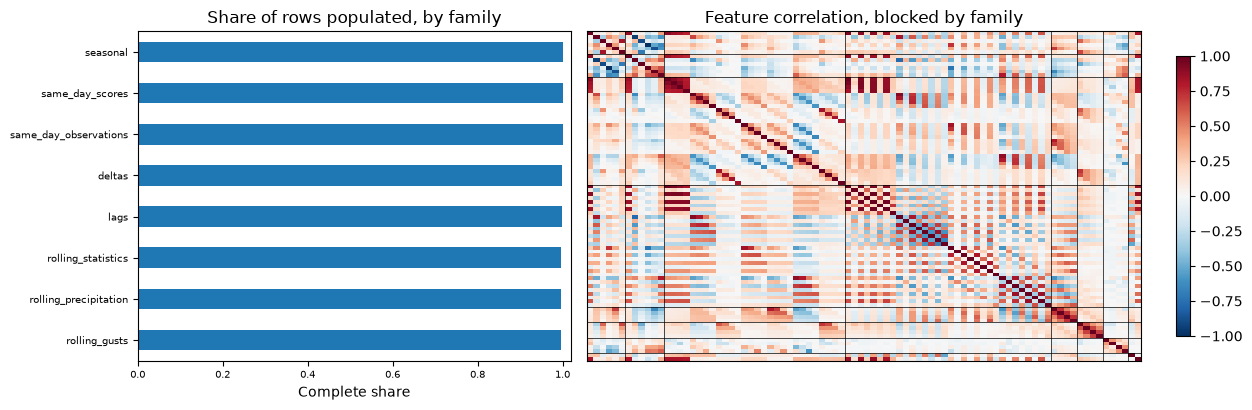

In [74]:
completeness = features.notna().mean().groupby(
    [next(family for family, columns in FEATURE_GROUPS.items() if column in columns)
     for column in features.columns]
).mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2),
                         gridspec_kw={"width_ratios": [1, 1.6]})
completeness.sort_values().plot.barh(ax=axes[0], color="tab:blue")
axes[0].set(title="Share of rows populated, by family", xlabel="Complete share", xlim=(0, 1.02))
axes[0].tick_params(labelsize=7)

ordered = [column for family in FEATURE_GROUPS for column in FEATURE_GROUPS[family]]
correlation = features[ordered].corr()
image = axes[1].imshow(correlation, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
boundary = 0
for family, columns in FEATURE_GROUPS.items():
    boundary += len(columns)
    axes[1].axhline(boundary - 0.5, color="black", lw=0.5)
    axes[1].axvline(boundary - 0.5, color="black", lw=0.5)
axes[1].set(title="Feature correlation, blocked by family", xticks=[], yticks=[])
fig.colorbar(image, ax=axes[1], shrink=0.85)
fig.tight_layout()
save_figure(fig, "features-39-matrix-overview")
plt.show()


## 4. Target alignment

For a feature row dated *t*, `cci_t1`, `cci_t2` and `cci_t3` hold the CCI observed on *t*+1,
*t*+2 and *t*+3. All three horizons sit on the same row so the modelling notebook can train
three models against an identical feature matrix and identical splits, making the cross-horizon
comparison a fair one.

Rows are dropped when the 30-day warm-up is incomplete, when any feature or target is missing
(a masked incomplete day), or at the tail of the series where the future is unobserved.

Alignment is verified by value: each target is compared against the CCI looked up at
`feature_date + horizon`. Asserting that `feature_date + h` is later than `feature_date` would
be true by construction and would not detect a positional shift landing on the wrong row.


In [75]:
targets = pd.DataFrame(index=daily.index)
for horizon in CCI_HORIZONS:
    targets[f"cci_t{horizon}"] = daily["cci"].shift(-horizon)
TARGET_COLUMNS = list(targets.columns)

for horizon in CCI_HORIZONS:
    expected = daily["cci"].reindex(targets.index + pd.Timedelta(days=horizon)).to_numpy()
    actual = targets[f"cci_t{horizon}"].to_numpy()
    if not np.array_equal(actual, expected, equal_nan=True):
        raise AssertionError(f"Horizon +{horizon} target does not match the CCI on that date.")
print("Alignment verified: each target equals the CCI observed on feature_date + horizon.")

dataset = features.join(targets)

# The first WARMUP_DAYS rows cannot have complete rolling windows.
warmup_cutoff = dataset.index.min() + pd.Timedelta(days=WARMUP_DAYS - 1)
dataset = dataset.loc[dataset.index > warmup_cutoff]

before = len(dataset)
dataset = dataset.dropna()
print(f"Dropped {before - len(dataset):,} row(s) with missing features or targets "
      f"(masked days and the final {MAX_HORIZON} dates).")

# The production cutoff is embargoed as well as filtered. Restricting only the feature date
# would leave the final rows carrying targets dated in 2026, which would draw the reserved
# production period into the test set through the target column.
dataset = dataset.loc[dataset.index < PRODUCTION_CUTOFF - pd.Timedelta(days=MAX_HORIZON)]
dataset.index.name = "feature_date"

latest_target = dataset.index.max() + pd.Timedelta(days=MAX_HORIZON)
if latest_target >= PRODUCTION_CUTOFF:
    raise AssertionError(f"Target dated {latest_target:%Y-%m-%d} falls in the production period.")
print(f"Modelling window: {dataset.index.min():%Y-%m-%d} to {dataset.index.max():%Y-%m-%d} "
      f"({len(dataset):,} rows); latest target {latest_target:%Y-%m-%d}")


Alignment verified: each target equals the CCI observed on feature_date + horizon.
Dropped 3 row(s) with missing features or targets (masked days and the final 3 dates).
Modelling window: 2016-01-31 to 2025-12-28 (3,620 rows); latest target 2025-12-31


### 4.1 Feature-target relationships

With the targets aligned, every feature can be related to what it is meant to predict. This is
the last diagnostic before splitting, and it produces three things the report needs.

**Correlation by horizon.** For each feature, the Pearson correlation with `cci_t1`, `cci_t2`
and `cci_t3`. The expected pattern is a systematic weakening as the horizon lengthens, since
atmospheric predictability decays; features that hold their correlation at *t*+3 are the ones
carrying genuine forecast signal rather than persistence.

**Ranked feature strength.** The top features by absolute correlation with `cci_t3`, the hardest
horizon. Correlation is univariate and linear, so it will understate features that matter only
in interaction — it is a screening view, not a substitute for the model's own importances.

**Scatter panels.** The relationship for the strongest features, which exposes non-linearity that
a correlation coefficient reduces to a single misleading number.

Note that this analysis is run on the **full modelling window**, before the split. It is used to
describe the data and to motivate the feature set, never to select features — doing the latter
on data that includes the test period would leak test information into the model through the
choice of columns.


Mean absolute correlation with each target, by family:
                       cci_t1  cci_t2  cci_t3
family                                       
deltas                   0.15    0.06    0.03
lags                     0.14    0.13    0.12
rolling_gusts            0.07    0.09    0.09
rolling_precipitation    0.15    0.09    0.06
rolling_statistics       0.19    0.16    0.14
same_day_observations    0.24    0.15    0.12
same_day_scores          0.33    0.21    0.15
seasonal                 0.17    0.18    0.18


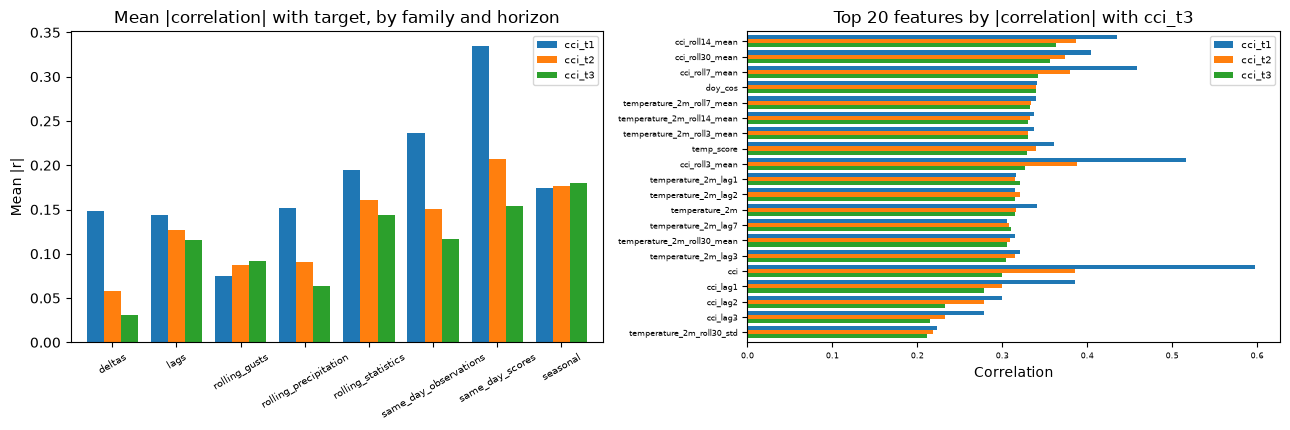

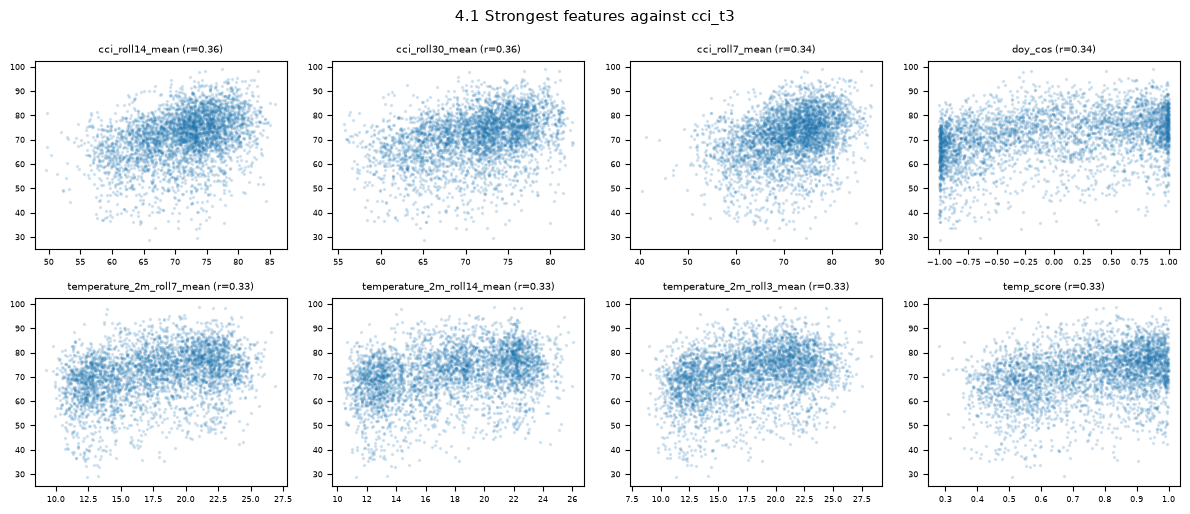

In [76]:
feature_target_correlation = pd.DataFrame(
    {target: dataset[FEATURE_COLUMNS].corrwith(dataset[target]) for target in TARGET_COLUMNS}
)
feature_target_correlation["family"] = [
    next(family for family, columns in FEATURE_GROUPS.items() if column in columns)
    for column in feature_target_correlation.index
]

family_strength = (
    feature_target_correlation.groupby("family")[TARGET_COLUMNS].apply(lambda g: g.abs().mean())
)
print("Mean absolute correlation with each target, by family:")
print(family_strength.to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
family_strength.plot.bar(ax=axes[0], width=0.8)
axes[0].set(title="Mean |correlation| with target, by family and horizon",
            ylabel="Mean |r|", xlabel="")
axes[0].tick_params(axis="x", labelrotation=30, labelsize=7)
axes[0].legend(fontsize=7)

top = feature_target_correlation["cci_t3"].abs().sort_values(ascending=False).head(20).index
feature_target_correlation.loc[top, TARGET_COLUMNS].plot.barh(ax=axes[1], width=0.8)
axes[1].invert_yaxis()
axes[1].set(title="Top 20 features by |correlation| with cci_t3", xlabel="Correlation")
axes[1].tick_params(labelsize=6)
axes[1].legend(fontsize=7)
fig.tight_layout()
save_figure(fig, "features-41-target-correlation")

strongest = list(top[:8])
fig, axes = _panel_grid(len(strongest), 4, panel_height=2.6)
for axis, column in zip(axes, strongest):
    axis.scatter(dataset[column], dataset["cci_t3"], s=2, alpha=0.15, color="tab:blue")
    correlation = dataset[column].corr(dataset["cci_t3"])
    axis.set_title(f"{column} (r={correlation:.2f})", fontsize=7)
    axis.set_xlabel("")
    axis.tick_params(labelsize=6)
fig.suptitle("4.1 Strongest features against cci_t3", fontsize=11)
fig.tight_layout()
save_figure(fig, "features-41-top-scatter")
plt.show()


## 5. Chronological split with embargo

Splits are by date, never shuffled: a random split would place future days in the training set
and inflate performance, because consecutive days are strongly autocorrelated.

| Split | Period |
| --- | --- |
| Train | start of the archive to end of 2023 |
| Validation | 2024 |
| Test | 2025 |
| Production (excluded) | 2026 onwards |

An **embargo** of `MAX_HORIZON` days is applied at each boundary. Without it, the final three
training rows carry targets dated inside the validation period, so validation outcomes would
already have been seen during training. The embargoed rows are discarded rather than reassigned.

Feature scaling and imputation are deliberately *not* applied here. Both must be fitted on the
training split only and applied to validation and test, so they belong inside the modelling
pipeline; fitting them across the full dataset would leak test-set distribution into training.


In [77]:
def chronological_split(
    frame: pd.DataFrame, val_start: pd.Timestamp, test_start: pd.Timestamp, embargo: int
) -> dict[str, pd.DataFrame]:
    """Split a date-indexed frame into train/validation/test with an embargo at each boundary.

    Parameters
    ----------
    frame
        Feature-and-target frame indexed by ``feature_date``.
    val_start, test_start
        First date of the validation and test periods.
    embargo
        Number of days removed before each boundary, so that no training row holds a target
        dated inside the following split.

    Returns
    -------
    dict
        Mapping of split name to frame.
    """
    gap = pd.Timedelta(days=embargo)
    return {
        "train": frame.loc[frame.index < val_start - gap],
        "val": frame.loc[(frame.index >= val_start) & (frame.index < test_start - gap)],
        "test": frame.loc[frame.index >= test_start],
    }


splits = chronological_split(dataset, VAL_START, TEST_START, MAX_HORIZON)

for name, frame in splits.items():
    if frame.empty:
        raise ValueError(f"Split '{name}' is empty; check the ingested date range and boundaries.")

# No training target may fall on or after the validation start, and likewise for validation.
train_target_max = splits["train"].index.max() + pd.Timedelta(days=MAX_HORIZON)
val_target_max = splits["val"].index.max() + pd.Timedelta(days=MAX_HORIZON)
if train_target_max >= VAL_START:
    raise AssertionError("A training target falls inside the validation period.")
if val_target_max >= TEST_START:
    raise AssertionError("A validation target falls inside the test period.")
print("Embargo verified: no split's targets reach into the following split.")

summary = pd.DataFrame(
    {
        "rows": {k: len(v) for k, v in splits.items()},
        "start": {k: v.index.min().date() for k, v in splits.items()},
        "end": {k: v.index.max().date() for k, v in splits.items()},
        "last_target_date": {
            k: (v.index.max() + pd.Timedelta(days=MAX_HORIZON)).date() for k, v in splits.items()
        },
        "mean_cci_t3": {k: v["cci_t3"].mean() for k, v in splits.items()},
    }
)
summary["share"] = summary["rows"] / summary["rows"].sum()
print()
print(summary.to_string(formatters={"share": "{:.1%}".format}))


Embargo verified: no split's targets reach into the following split.

       rows       start         end last_target_date  mean_cci_t3 share
train  2889  2016-01-31  2023-12-28       2023-12-31        71.30 79.9%
val     363  2024-01-01  2024-12-28       2024-12-31        69.65 10.0%
test    362  2025-01-01  2025-12-28       2025-12-31        71.25 10.0%


## 6. Leakage verification

The guarantee that no feature depends on the future is checked empirically rather than asserted.
Features are rebuilt from a series **truncated at a sample date**, and the resulting row is
compared against the same row built from the full series. If any feature looked ahead, the two
would differ, because the truncated series has no future to look at.

This is the test that would catch an accidental `center=True`, a negative shift, or a
full-series transformation such as a global mean fill.


In [78]:
rng = np.random.default_rng(0)
sample_dates = pd.DatetimeIndex(
    rng.choice(dataset.index[dataset.index > dataset.index.min() + pd.Timedelta(days=WARMUP_DAYS)],
               size=min(25, len(dataset) - WARMUP_DAYS), replace=False)
).sort_values()

mismatches: list[str] = []
for date in sample_dates:
    truncated, _ = build_features(daily.loc[:date])
    full_row = features.loc[date]
    truncated_row = truncated.loc[date]
    differing = full_row.index[~np.isclose(full_row.to_numpy(dtype=float),
                                           truncated_row.to_numpy(dtype=float),
                                           equal_nan=True)]
    mismatches.extend(f"{date:%Y-%m-%d}: {column}" for column in differing)

if mismatches:
    raise AssertionError(
        f"{len(mismatches)} feature value(s) changed when future data was removed, "
        f"indicating leakage. Examples: {mismatches[:5]}"
    )
print(f"No leakage detected across {len(sample_dates)} sampled dates "
      f"x {len(FEATURE_COLUMNS)} features.")

persistence = pd.DataFrame(
    {
        "corr_with_cci_t": [splits["train"]["cci"].corr(splits["train"][f"cci_t{h}"]) for h in CCI_HORIZONS],
        "target_std": [splits["train"][f"cci_t{h}"].std() for h in CCI_HORIZONS],
    },
    index=pd.Index(CCI_HORIZONS, name="horizon_days"),
)
print("\nPersistence reference (training split) - the floor the models must clear:")
print(persistence.to_string())


No leakage detected across 25 sampled dates x 86 features.

Persistence reference (training split) - the floor the models must clear:
              corr_with_cci_t  target_std
horizon_days                             
1                        0.59       10.26
2                        0.37       10.26
3                        0.27       10.26


## 7. Outputs

Each split is written with its `feature_date` index, all feature columns and the three targets.
`cci_feature_metadata.json` records the feature groups, target names, split boundaries and
embargo so the modelling notebook can reproduce the ablation without re-deriving the
definitions, and so the API can validate that a served feature vector has the expected columns
in the expected order.


In [79]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

for name, frame in splits.items():
    path = PROCESSED_DIR / f"sydney_cci_{name}.csv"
    frame.to_csv(path, index_label="feature_date")
    print(f"{name:<5} {len(frame):>6,} rows -> {path.relative_to(PROJECT_ROOT)}")

metadata = {
    "student_id": "25945320",
    "target": "Climate Comfort Index",
    "prediction_type": "regression",
    "horizons_days": list(CCI_HORIZONS),
    "target_columns": TARGET_COLUMNS,
    "feature_columns": FEATURE_COLUMNS,
    "feature_groups": FEATURE_GROUPS,
    "daily_aggregations": aggregations,
    "warmup_days": WARMUP_DAYS,
    "embargo_days": MAX_HORIZON,
    "split_boundaries": {
        "val_start": VAL_START.strftime("%Y-%m-%d"),
        "test_start": TEST_START.strftime("%Y-%m-%d"),
        "production_cutoff": PRODUCTION_CUTOFF.strftime("%Y-%m-%d"),
    },
    "split_rows": {k: len(v) for k, v in splits.items()},
}
metadata_path = PROCESSED_DIR / "cci_feature_metadata.json"
metadata_path.write_text(json.dumps(metadata, indent=2))
print(f"\nmetadata   -> {metadata_path.relative_to(PROJECT_ROOT)}")


train  2,889 rows -> data/processed/comfort_climate/sydney_cci_train.csv
val      363 rows -> data/processed/comfort_climate/sydney_cci_val.csv
test     362 rows -> data/processed/comfort_climate/sydney_cci_test.csv

metadata   -> data/processed/comfort_climate/cci_feature_metadata.json


### Output contract

| File | Contents |
| --- | --- |
| `data/interim/comfort_climate/sydney_daily_cci_inputs.csv` | Daily aggregates for the full archive window, including the reserved production period. Auditing artefact for the aggregation step. |
| `data/processed/comfort_climate/sydney_cci_train.csv` | Features and `cci_t1/t2/t3` targets, archive start to end of 2023 less embargo. |
| `data/processed/comfort_climate/sydney_cci_val.csv` | As above, 2024. |
| `data/processed/comfort_climate/sydney_cci_test.csv` | As above, 2025. Touched only for final evaluation. |
| `data/processed/comfort_climate/cci_feature_metadata.json` | Feature families and their columns, target names, aggregation rules, split boundaries, embargo. |

**For the modelling notebook**

- Load the three splits as-is; do not re-split or shuffle.
- Fit scalers and any imputation on `train` only.
- Use `val` for model selection and hyperparameter search; touch `test` once, at the end.
- Report metrics per horizon rather than averaged — skill is expected to decay with lead time.
- Run the family ablation using `feature_groups` from the metadata file, so the contribution of
  each engineered family is measured rather than assumed.
- Baselines to beat: predict `cci` at *t* (persistence), and predict the seasonal day-of-year
  mean from the training split (climatology).
